<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 12 · Classical models</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Exponential smoothing (ETS) and ARIMA are the two classical families of forecasting models. ETS is a weighted average with geometrically shrinking weights, plus trend and season; ARIMA regresses a differenced series on its own past values and errors. Both give a likelihood for choosing models, prediction intervals, and the baselines as special cases. On synthetic weekly harvests, a seasonal ARIMA had the lowest error in all 10 simulated histories when the season kept its calendar: $5.0$ t/week averaged over 1 to 8 weeks ahead, against $7.2$ for seasonal naive and $6.5$ for gradient boosting. When the peak moved from year to year, gradient boosting won 7 of 10 histories, and the classical 80% intervals held only $66$–$72\%$ of outcomes. Afterwards you should be able to fit both families to a weekly series, read their orders, add them to a backtest beside seasonal naive, and check their intervals before trusting them.
:::

In [1]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")  # optimiser and progress-bar chatter from statsmodels and statsforecast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsforecast
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingRegressor
from statsforecast.models import AutoARIMA, AutoETS
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf

here = [Path.cwd(), *Path.cwd().parents]  # fallcolor: the site's colour module in tools/
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P = 52  # weeks per season

## Exponential smoothing

**Simple exponential smoothing** forecasts next week as a weighted average of all past weeks, with weights that shrink by a constant factor per week back[^1]:

$$\hat{y}_{t+1 \mid t} = \alpha y_t + \alpha (1-\alpha) y_{t-1} + \alpha (1-\alpha)^2 y_{t-2} + \cdots$$

where $y_t$ is the volume in week $t$ (t/week), $\hat{y}_{t+1 \mid t}$ the forecast for week $t+1$ made at week $t$, and $\alpha$ (0 to 1, no units) the **smoothing parameter**: with $\alpha = 0.3$ the weights run $0.3$, $0.3 \times 0.7 = 0.21$, $0.21 \times 0.7 = 0.147$. At $\alpha = 1$ all the weight is on $y_t$: the naive forecast of [Baselines first](../baselines-first.qmd).

- **Holt's method** adds a smoothed **trend**; a **damped trend** shrinks it at each step ahead, so long forecasts level off.
- **Holt–Winters** adds a **season**: one number per week of the season, 52 for weekly data, each updated when that week comes round. **Additive** seasonal numbers are tonnes added to the level; **multiplicative** ones are factors, roughly additive on the log scale of [Log and Box–Cox transforms](../log-and-boxcox-transforms.qmd).

Written with an explicit random error, each method becomes a state-space model, named **ETS(error, trend, season)** with letters N (none), A (additive), Ad (damped) or M (multiplicative)[^2]. That is what lets you compare models by AICc and get prediction intervals; you do not need the equations to use them. ETS(A,N,A) is additive Holt–Winters without a trend.

::: {.callout-note collapse="true"}
## The equations of ETS(A,N,A)

$$y_t = \ell_{t-1} + s_{t-m} + \varepsilon_t, \qquad \ell_t = \ell_{t-1} + \alpha \varepsilon_t, \qquad s_t = s_{t-m} + \gamma \varepsilon_t$$

where $\ell_t$ is the level (t/week), $s_t$ the seasonal effect of week $t$ (t/week), $m = 52$ the season length in weeks, $\varepsilon_t$ a random error with mean zero and standard deviation $\sigma$ (t/week), and $\alpha$ and $\gamma$ (no units) the shares of each surprise that go into the level and into that week's seasonal effect. The forecast $h \le m$ weeks ahead is $\ell_t + s_{t+h-m}$, with variance $\sigma^2 [1 + (h-1)\alpha^2]$ (Hyndman and Athanasopoulos, Table 8.7). Lower $\text{AICc} = \text{AIC} + 2k(k+1)/(T-k-1)$ is better, with $k$ estimated parameters and $T$ weeks.
:::

The data are **synthetic**: six 52-week seasons of weekly harvest (t/week) from a fixed seed, a bell-shaped harvest each season plus autocorrelated noise. In the **regular** series the peak is always in week 26; in the **shifting** series its week varies with a standard deviation of 4 weeks.

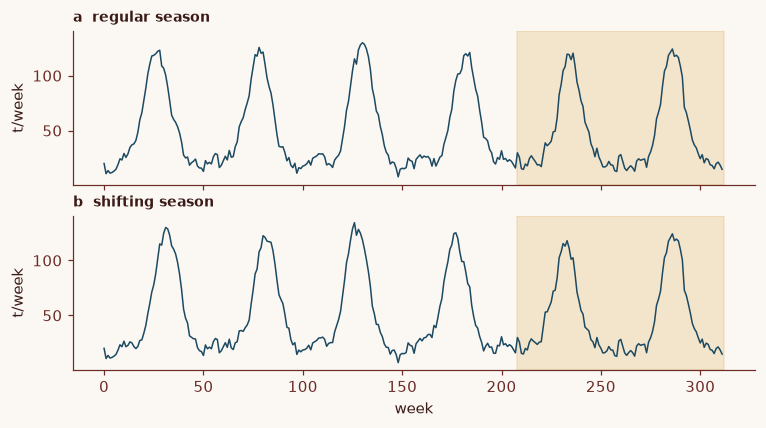

In [2]:
def simulate(seed, shift_sd, seasons=6):
    """Synthetic weekly harvest (t/week): one bell-shaped season per 52 weeks."""
    rng = np.random.default_rng(seed)
    t = np.arange(seasons * P)
    size = rng.normal(100, 10, seasons)  # peak height, varies by season
    peak = 26 + rng.normal(0, shift_sd, seasons)  # week of peak; fixed if shift_sd = 0
    shape = np.exp(-0.5 * ((t % P - peak[t // P]) / 6) ** 2)
    noise = np.zeros(len(t))
    for i in range(1, len(t)):  # AR(1): a good week tends to follow a good week
        noise[i] = 0.6 * noise[i - 1] + rng.normal(0, 4)
    return pd.Series(np.clip(20 + size[t // P] * shape + noise, 0, None))


regular, shifting = simulate(0, shift_sd=0), simulate(0, shift_sd=4)
fig, axes = plt.subplots(2, 1, figsize=(8, 4), sharex=True, sharey=True)
for ax, y, label in zip(axes, [regular, shifting], ["a  regular season", "b  shifting season"]):
    ax.plot(y, color=C1, lw=1)
    ax.axvspan(4 * P, 6 * P, color=C2, alpha=0.2)
    ax.set_title(label, loc="left", fontsize=9, fontweight="bold")
    ax.set(ylabel="t/week", xlabel="week" if ax is axes[1] else "")
plt.show()

**Figure 1 | The two synthetic series.** **a**, Regular season. **b**, Shifting season. Shaded: seasons 5 and 6, forecast in the backtest below. One of 10 simulated histories of each.

Three ETS models on the first four seasons of the regular series:

In [3]:
train = regular[: 4 * P]  # a plain gap-free weekly pd.Series; four seasons, as at the first origin
specs = {"ETS(A,N,A)": ("add", None, "add"), "ETS(A,Ad,A)": ("add", "add", "add"), "ETS(M,N,M)": ("mul", None, "mul")}
table = {}
for name, (error, trend, season) in specs.items():
    fit = ETSModel(train, error=error, trend=trend, damped_trend=trend is not None, seasonal=season,
                   seasonal_periods=P, initialization_method="heuristic").fit(disp=False)
    params = dict(zip(fit.param_names, fit.params))
    table[name] = {"AICc": fit.aicc, "alpha": params["smoothing_level"], "gamma": params["smoothing_seasonal"]}
pd.DataFrame(table).T.round(3)

,AICc,alpha,gamma
"ETS(A,N,A)",1154.218,0.848,0.0
"ETS(A,Ad,A)",1158.493,0.848,0.0
"ETS(M,N,M)",1321.043,0.744,0.0


ETS(A,N,A) has the lowest AICc, $1154.2$ against $1158.5$ and $1321.0$. Its $\alpha = 0.848$ means the level follows the latest weeks closely. Read $\gamma$ as how much each season rewrites the seasonal shape: near 0 it is learned once and held, near 1 it is re-learned from the latest season. Here $\gamma = 0.0$, which suits a season that never moves.

One trap: asked for a 52-week season, statsforecast's `AutoETS` does not refuse.

In [4]:
auto = AutoETS(season_length=P).fit(train.to_numpy())
print(f"statsforecast {statsforecast.__version__} AutoETS chose:",
      auto.model_["components"])  # error, trend, season, damped

statsforecast 2.0.1 AutoETS chose: AAND


`AAND` is additive error, additive trend, **no season**, damped: the season was dropped silently. That output is the evidence. The reason comes from reading the statsforecast 2.0.1 source, not its documentation: its ETS code stops when a seasonal period exceeds 24. Check the components of any automatic fit.

## ARIMA

ARIMA makes the series **stationary**, with a mean, spread and correlation pattern that do not change over time, then regresses it on its own past:

- **Differencing (I, order $d$)**: model the change $y_t - y_{t-1}$. The **seasonal difference** $y_t - y_{t-52}$ removes a repeating seasonal shape.
- **Autoregressive terms (AR, order $p$)**: regress on the last $p$ values.
- **Moving-average terms (MA, order $q$)**: regress on the last $q$ forecast errors.

**ARIMA($p$,$d$,$q$)($P$,$D$,$Q$)$_m$** adds the same at multiples of the seasonal lag $m$.

The ACF and PACF of the differenced series, defined in [Lags and rolling windows](../lags-and-rolling-windows/lags_and_rolling_windows.ipynb), narrow the choice: a PACF spike at lag $p$ and none beyond suggests AR($p$); an ACF that cuts off at lag $q$ suggests MA($q$) (Hyndman and Athanasopoulos, Section 9.5). In practice `AutoARIMA` decides by AICc, and the plots sanity-check its answer.

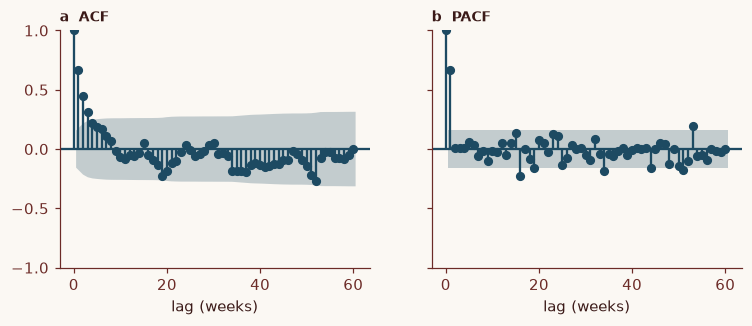

ACF at lags 1, 2, 52: [ 0.67  0.45 -0.27]


In [5]:
seasonal_diff = (train - train.shift(P)).dropna()  # y[t] - y[t-52]
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for ax, plot, title in zip(axes, [plot_acf, plot_pacf], ["a  ACF", "b  PACF"]):
    plot(seasonal_diff, lags=60, ax=ax, title="", color=C1, vlines_kwargs={"colors": C1})
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold")
    ax.set(xlabel="lag (weeks)")
plt.show()
print("ACF at lags 1, 2, 52:", acf(seasonal_diff, nlags=52)[[1, 2, 52]].round(2))

**Figure 2 | Reading the orders.** **a**, ACF and **b**, PACF of $y_t - y_{t-52}$, first four seasons of the regular series. Shaded: approximate 95% band for a series with no autocorrelation.

The ACF decays from $0.67$ at lag 1 and the PACF has one large spike at lag 1: AR(1). At lag 52 the ACF is $-0.27$, inside the widening band, a weak hint of a seasonal MA term. `AutoARIMA`:

In [6]:
start = time.perf_counter()
p, q, sp, sq, m, d, sd = AutoARIMA(season_length=P).fit(train.to_numpy()).model_["arma"]
print(f"AutoARIMA chose ARIMA({p},{d},{q})({sp},{sd},{sq})[{m}] in {time.perf_counter() - start:.0f} s")
start = time.perf_counter()
sarima = SARIMAX(train, order=(1, 0, 0), seasonal_order=(0, 1, 1, P)).fit(disp=False)
print(f"refitting that order alone: {time.perf_counter() - start:.1f} s")
print(sarima.params.round(3).to_dict())  # ar.L1 = phi_1, ma.S.L52 = Theta_1

AutoARIMA chose ARIMA(1,0,0)(0,1,1)[52] in 12 s


refitting that order alone: 1.0 s
{'ar.L1': 0.705, 'ma.S.L52': -0.851, 'sigma2': 17.965}


It keeps the seasonal MA term. The AR coefficient is $\phi_1 = 0.705$, near the $0.6$ used to simulate the noise, and the seasonal MA coefficient $\Theta_1 = -0.851$ (both unitless). The search is slow with a 52-week season, so the backtest fixes this order and re-estimates only the coefficients.

**The baselines are ARIMA models** with nothing estimated (Hyndman and Athanasopoulos, Table 9.1): naive is ARIMA(0,1,0), drift is ARIMA(0,1,0) with a constant, and seasonal naive is ARIMA(0,0,0)(0,1,0)$_{52}$. Fitted to the same four seasons:

In [7]:
v, h = train.to_numpy(), np.arange(1, 9)
checks = {  # name: (ARIMA model, the baseline computed by hand)
    "naive = ARIMA(0,1,0)": (ARIMA(train, order=(0, 1, 0)), np.repeat(v[-1], 8)),
    "seasonal naive = ARIMA(0,0,0)(0,1,0)[52]": (ARIMA(train, seasonal_order=(0, 1, 0, P)), v[len(v) - P + h - 1]),
    "drift = ARIMA(0,1,0) + constant": (ARIMA(train, order=(0, 1, 0), trend="t"), v[-1] + h * (v[-1] - v[0]) / (len(v) - 1)),
}
for name, (model, baseline) in checks.items():
    gap = np.abs(model.fit().forecast(8).to_numpy() - baseline).max()
    print(f"{name}: largest difference {gap:.4f} t/week")

naive = ARIMA(0,1,0): largest difference 0.0000 t/week
seasonal naive = ARIMA(0,0,0)(0,1,0)[52]: largest difference 0.0000 t/week
drift = ARIMA(0,1,0) + constant: largest difference 0.0000 t/week


The classical models are these baselines with their weights estimated.

::: {.callout-note collapse="true"}
## More equivalences, and what $\Theta_1$ means

Simple exponential smoothing is ARIMA(0,1,1) with MA coefficient $\theta_1 = \alpha - 1$, Holt's method is ARIMA(0,2,2), and the damped trend ARIMA(1,1,2) (Hyndman and Athanasopoulos, Table 9.4). Applying the first equivalence one season apart, which is this module's extension rather than the book's statement, the seasonal difference with one seasonal MA term, $y_t - y_{t-52} = \varepsilon_t + \Theta_1 \varepsilon_{t-52}$, forecasts

$$\hat{y}_{t+52 \mid t} = (1 + \Theta_1)\, y_t - \Theta_1\, \hat{y}_{t \mid t-52}$$

where $\varepsilon_t = y_t - \hat{y}_{t \mid t-52}$ is the one-season-ahead error (t/week): smoothing of each week across seasons with $\alpha = 1 + \Theta_1$, from copying last season ($\Theta_1 = 0$) to averaging all seasons ($\Theta_1 \to -1$). Here $1 - 0.851 = 0.149$.
:::

## A backtest on weekly harvests

As in [Backtesting properly](../backtesting/backtesting_properly.ipynb): origins every fourth week through seasons 5 and 6, every model refitted at each origin, mean absolute error (MAE, t/week) at $h = 1$ to 8. The models: seasonal naive, with an 80% interval of $\pm 1.28$ standard deviations of its past errors; ETS(A,N,A) and ARIMA(1,0,0)(0,1,1)$_{52}$ (SARIMA), with their own intervals; and gradient boosting, one model per horizon, with the features of the backtesting module. Each series is simulated 10 times.

In [8]:
FEATS = ["y_t", "y_t-1", "y_t-2", "last_season", "week"]


def gbm_forecast(y, origin, h):
    """Direct gradient-boosted forecast of y[origin + h], as in Backtesting properly."""
    d = pd.DataFrame({"y_t": y, "y_t-1": y.shift(1), "y_t-2": y.shift(2), "last_season": y.shift(P - h),
                      "week": (y.index + h) % P, "target": y.shift(-h)})
    known = d.iloc[: origin - h + 1].dropna()  # rows whose target was observed by the origin
    fit = HistGradientBoostingRegressor(random_state=0).fit(known[FEATS], known["target"])
    return fit.predict(d.loc[[origin], FEATS])[0]


def forecast_all(y, origin, H=8):
    """Forecasts of weeks origin+1 ... origin+H, with 80% intervals. Your inputs: y, a gap-free
    weekly pd.Series; H, the horizons you issue; P, the season length, set at the top."""
    hist, steps = y[: origin + 1], np.arange(1, H + 1)
    out = pd.DataFrame({"h": steps, "actual": y.iloc[origin + steps].values, "snaive": y.iloc[origin + steps - P].values})
    half = 1.2816 * (hist - hist.shift(P)).std()  # z(80%) x seasonal-naive residual sd
    out["snaive_lo"], out["snaive_hi"] = out.snaive - half, out.snaive + half
    ets = ETSModel(hist, error="add", seasonal="add", seasonal_periods=P, initialization_method="heuristic").fit(disp=False)
    f = ets.get_prediction(origin + 1, origin + H).summary_frame(alpha=0.2)
    out["ets"], out["ets_lo"], out["ets_hi"] = f["mean"].values, f["pi_lower"].values, f["pi_upper"].values
    sar = SARIMAX(hist, order=(1, 0, 0), seasonal_order=(0, 1, 1, P)).fit(disp=False).get_forecast(H)
    ci = np.asarray(sar.conf_int(alpha=0.2))
    out["sarima"], out["sarima_lo"], out["sarima_hi"] = np.asarray(sar.predicted_mean), ci[:, 0], ci[:, 1]
    out["gbm"] = [gbm_forecast(y, origin, h) for h in steps]
    return out


def backtest(seed, shift_sd):
    warnings.filterwarnings("ignore")  # each parallel worker starts with fresh filters
    y = simulate(seed, shift_sd)
    origins = range(4 * P - 1, 6 * P - 8, 4)  # every fourth week of seasons 5 and 6; set for your history
    runs = pd.concat([forecast_all(y, o).assign(origin=o) for o in origins])
    return runs.assign(seed=seed, series="regular" if shift_sd == 0 else "shifting")


bt = pd.concat(Parallel(n_jobs=-1)(delayed(backtest)(seed, sd) for sd in (0, 4) for seed in range(10)))
print(f"{len(bt):,} forecasts: 2 series x 10 histories x {bt.origin.nunique()} origins x 8 horizons")

4,000 forecasts: 2 series x 10 histories x 25 origins x 8 horizons


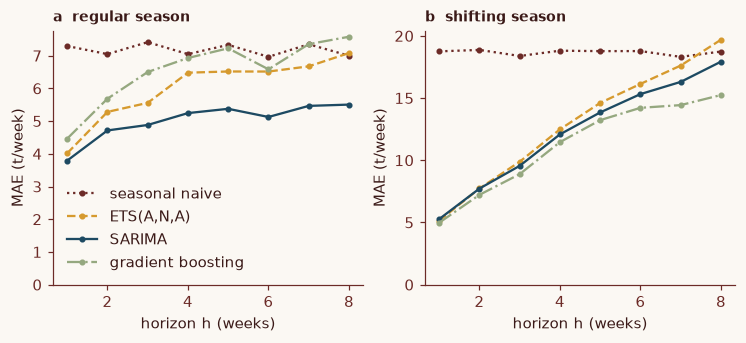

series            regular      shifting      
h                       1    8        1     8
seasonal naive        7.3  7.0     18.8  18.7
ETS(A,N,A)            4.0  7.1      5.1  19.7
SARIMA                3.8  5.5      5.3  17.9
gradient boosting     4.5  7.6      5.0  15.2

In [9]:
MODELS = {"snaive": "seasonal naive", "ets": "ETS(A,N,A)", "sarima": "SARIMA", "gbm": "gradient boosting"}
err = bt[list(MODELS)].sub(bt.actual, axis=0).abs().assign(series=bt.series, h=bt.h, seed=bt.seed)
mae = err.groupby(["series", "h"])[list(MODELS)].mean().rename(columns=MODELS)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, series, label in zip(axes, ["regular", "shifting"], "ab"):
    mae.loc[series].plot(ax=ax, color=[C3, C2, C1, C4], style=[":o", "--o", "-o", "-.o"], ms=3, legend=label == "a")
    ax.set_title(f"{label}  {series} season", loc="left", fontsize=9, fontweight="bold")
    ax.set(xlabel="horizon h (weeks)", ylabel="MAE (t/week)", ylim=(0, None))
plt.show()
mae.loc[(slice(None), [1, 8]), :].T.round(1)  # columns: series, horizon

**Figure 3 | Error by horizon.** MAE over origins in seasons 5 and 6 and 10 simulated histories. **a**, Regular. **b**, Shifting. Table: $h = 1$ and $h = 8$.

The SARIMA order was chosen once, by AutoARIMA on one regular history, and fixed for all 20 backtests, shifting ones included, which may flatter SARIMA slightly.

**Regular season: SARIMA wins at every horizon.** At $h = 1$ the fitted models beat seasonal naive, $3.8$–$4.5$ against $7.3$ t/week. By $h = 8$, ETS and gradient boosting are back near seasonal naive ($7.1$ and $7.6$ against $7.0$), while SARIMA keeps a lead of $7.0 - 5.5 = 1.5$ t/week. SARIMA's AR term lets a surprise fade, as the simulated noise does; ETS ($\alpha = 0.848$) moves its level by most of a surprise and keeps it.

**Shifting season: nobody wins easily.** At $h = 1$ the fitted models tie at $5.0$–$5.3$ t/week; seasonal naive, copying a peak that has moved, is at $18.8$. At $h = 8$ gradient boosting leads with $15.2$, then SARIMA $17.9$, seasonal naive $18.7$ and ETS $19.7$. Averaged over all horizons:

In [10]:
per_seed = err.groupby(["series", "seed"])[list(MODELS)].mean()  # MAE over h = 1-8
print(per_seed.groupby("series").mean().rename(columns=MODELS).round(1).to_string())
best = per_seed.idxmin(axis=1).map(MODELS)
print("\nbest model per history:", best.groupby("series").value_counts().to_dict())

          seasonal naive  ETS(A,N,A)  SARIMA  gradient boosting
series                                                         
regular              7.2         6.0     5.0                6.5
shifting            18.7        12.9    12.3               11.2

best model per history: {('regular', 'SARIMA'): 10, ('shifting', 'gradient boosting'): 7, ('shifting', 'SARIMA'): 2, ('shifting', 'ETS(A,N,A)'): 1}


SARIMA was best in all 10 regular histories, gradient boosting in 7 of 10 shifting ones. The classical models hold one seasonal shape, an average of past calendars, so a moved peak is pure error to them. Why the trees do better is untested here; a likely reason is that they see this week's volume and week of season together.

An 80% interval should contain about 80% of outcomes. The share that did:

In [11]:
inside = pd.DataFrame({MODELS[m]: bt.actual.between(bt[f"{m}_lo"], bt[f"{m}_hi"])
                       for m in ["snaive", "ets", "sarima"]}).assign(series=bt.series)
inside.groupby("series").mean().T.round(2)  # share of actuals inside the 80% interval

series,regular,shifting
seasonal naive,0.82,0.78
"ETS(A,N,A)",0.74,0.66
SARIMA,0.83,0.72


On the regular season SARIMA's intervals held $83\%$ and seasonal naive's $82\%$; ETS's held $74\%$. On the shifting season all three fell short: $78\%$, $66\%$ and $72\%$ for seasonal naive, ETS and SARIMA. A model-based interval assumes the model is right. If an interval sets safety stock, measure its coverage on the backtest first, or fit quantiles directly as in [Pinball loss and quantiles](../pinball-loss-and-quantiles.qmd).

## Where weekly produce strains them

**Long seasons and short histories.** The seasonal ARIMA search took $12$ s for one fit, a seasonal difference spends a whole season of history, and a calendar year is $365.25 / 7 = 52.18$ weeks, not 52. For short histories or seasons that are not 52 weeks, the usual route is dynamic harmonic regression: a few sine–cosine (Fourier) pairs as regressors with ARIMA errors (Hyndman and Athanasopoulos, Section 13.1). [Calendar and cyclical encodings](../calendar-encodings/calendar_and_cyclical_encodings.ipynb) builds Fourier and spline terms.

**Seasons that move.** To check yours, print the peak week of each season, `y.groupby(season).idxmax()`, or the first week each season passes a set volume, and see how far they spread. All four models here read the season by calendar week; to follow a moving season, a model needs an input that moves with it: weeks since first harvest, accumulated heat, or last season re-aligned, as in the aligned seasonal naive of [Baselines first](../baselines-first.qmd). Drivers such as degree-days can enter ARIMA as regressors (ARIMAX, the `exog` argument of `SARIMAX`), but you then need their future values; when the classical model is still the better choice is the subject of the next module, *When classical beats machine learning*.

**What this means for you.** Put a seasonal ARIMA in your backtest beside seasonal naive, order chosen once with `AutoARIMA`. Here it cut the mean error from $7.2$ to $5.0$ t/week; if your gradient-boosted model does not beat it, your features are missing what seasonal structure gives for free. Measure interval coverage before using the intervals: SARIMA's fell to $72\%$ for a nominal 80% once the season moved.

## Key takeaways

- ETS is exponential smoothing written as a model, which gives it AICc for model choice and prediction intervals.
- ARIMA regresses a differenced series on past values and errors; ACF and PACF narrow the orders, AutoARIMA decides.
- Naive, drift and seasonal naive are ARIMA models with nothing estimated.
- With a fixed seasonal calendar, SARIMA won in all 10 synthetic histories. With a moving peak, gradient boosting won 7 of 10, and the classical 80% intervals covered $66$–$72\%$.
- With 52-week seasons, check what an automatic fit chose and consider Fourier terms.

## References

[^1]: Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice* 3rd edn, Chapters 8 and 9 and Section 13.1 (OTexts, 2021).
[^2]: Hyndman, R. J., Koehler, A. B., Snyder, R. D. & Grose, S. A state space framework for automatic forecasting using exponential smoothing methods. *Int. J. Forecast.* **18**, 439–454 (2002). https://doi.org/10.1016/S0169-2070(01)00110-8

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/many-series/forecasting_many_series.html"><span>Previous</span>Forecasting many series at once</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/retraining-and-drift/retraining_and_drift.html"><span>Next</span>Retraining and drift</a></div>
<!-- CURRICULUM_FOOTER_END -->